<a href="https://colab.research.google.com/github/Separd-sudo/evaluacion1-deep-learning-mlp/blob/develop/Evaluacion_MLP_Dataset_BankMarketing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evaluación — Red Neuronal Multicapa (MLP) para clasificación
## Dataset: *Bank Marketing* (UCI Machine Learning Repository)

### Contexto del problema

Un banco portugués realizó **campañas de marketing telefónico** para ofrecer a sus clientes un **depósito a plazo**. Por cada cliente contactado se registraron sus datos personales, su situación financiera y el historial de contactos de la campaña.

**Objetivo:** construir un modelo que prediga si un cliente **contratará el depósito a plazo** (`y = "yes"`) o **no** (`y = "no"`).

| | |
|---|---|
| **Tipo de problema** | Clasificación **binaria** |
| **Registros** | 45.211 clientes |
| **Variables de entrada** | 16 (7 numéricas y 9 categóricas) |
| **Variable objetivo** | `y` ("yes" / "no") |
| **Fuente** | [UCI Machine Learning Repository — Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing) |
| **Licencia** | CC BY 4.0 |
| **Cita** | Moro, S., Cortez, P. & Rita, P. (2014). *A data-driven approach to predict the success of bank telemarketing.* Decision Support Systems, 62, 22–31. |

## ¿Qué deben demostrar?

1. Cargar y **preprocesar** correctamente los datos.
2. **Diseñar e implementar** una arquitectura MLP (TensorFlow/Keras o PyTorch).
3. Configurar **parámetros de entrenamiento**: épocas, tasa de aprendizaje y tamaño de batch.
4. **Comparar** distintas funciones de **activación** y funciones de **pérdida**.
5. Aplicar técnicas de **optimización** y **regularización**.
6. **Evaluar** el desempeño con **Accuracy, Precision, Recall y F1-Score**.
7. **Analizar** los resultados y **justificar** las mejoras realizadas al modelo.

> Este notebook **solo carga y describe los datos**. Todo el preprocesamiento, el modelo y el análisis son parte de su trabajo.

## 1. Cargar los datos

Ejecuta **una** de las dos opciones.

**Opción A (recomendada): descarga directa desde UCI.** Funciona en Google Colab y en Jupyter local. Solo requiere internet.

In [1]:
import io
import zipfile
import urllib.request

import pandas as pd
import matplotlib.pyplot as plt

URL_UCI = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

with urllib.request.urlopen(URL_UCI) as resp:
    zip_externo = zipfile.ZipFile(io.BytesIO(resp.read()))
zip_interno = zipfile.ZipFile(io.BytesIO(zip_externo.read("bank.zip")))   # el archivo viene comprimido dos veces
df = pd.read_csv(zip_interno.open("bank-full.csv"), sep=";")

print("Datos cargados:", df.shape[0], "filas x", df.shape[1], "columnas")

Datos cargados: 45211 filas x 17 columnas


**Opción B: desde el archivo `bank_marketing.csv` entregado por el docente.**

- **En Colab:** sube el archivo con el ícono de carpeta (panel izquierdo → *Subir*) y ejecuta la celda.
- **En Jupyter local:** deja el CSV en la misma carpeta que este notebook.
- **Desde un enlace** (Google Drive / GitHub): pega el enlace en `ENLACE`. Si es de Google Drive, el archivo debe estar compartido como *"Cualquier persona con el enlace"*.

In [ ]:
ENLACE = ""   # opcional: pega aquí el enlace entregado por el docente

def enlace_descarga(url):
    # Convierte un enlace "compartir" de Google Drive en un enlace de descarga directa
    if "drive.google.com" in url and "/d/" in url:
        file_id = url.split("/d/")[1].split("/")[0]
        return f"https://drive.google.com/uc?export=download&id={file_id}"
    return url

df = pd.read_csv(enlace_descarga(ENLACE) if ENLACE else "bank_marketing.csv")
print("Datos cargados:", df.shape[0], "filas x", df.shape[1], "columnas")

## 2. Diccionario de variables

**Datos del cliente**

| Variable | Tipo | Descripción |
|---|---|---|
| `age` | numérica | Edad |
| `job` | categórica | Tipo de trabajo (`admin.`, `blue-collar`, `entrepreneur`, `housemaid`, `management`, `retired`, `self-employed`, `services`, `student`, `technician`, `unemployed`, `unknown`) |
| `marital` | categórica | Estado civil (`married`, `single`, `divorced` — "divorced" incluye viudos) |
| `education` | categórica | Nivel educacional (`primary`, `secondary`, `tertiary`, `unknown`) |
| `default` | binaria | ¿Tiene créditos en mora? (`yes` / `no`) |
| `balance` | numérica | Saldo promedio anual, en euros (puede ser negativo) |
| `housing` | binaria | ¿Tiene crédito hipotecario? |
| `loan` | binaria | ¿Tiene crédito de consumo? |

**Último contacto de la campaña actual**

| Variable | Tipo | Descripción |
|---|---|---|
| `contact` | categórica | Medio de contacto (`cellular`, `telephone`, `unknown`) |
| `day` | numérica | Día del mes del último contacto |
| `month` | categórica | Mes del último contacto (`jan` … `dec`) |
| `duration` | numérica | Duración del último contacto, en segundos ⚠️ *(ver nota importante más abajo)* |

**Otros atributos**

| Variable | Tipo | Descripción |
|---|---|---|
| `campaign` | numérica | N° de contactos realizados a este cliente en esta campaña (incluye el último) |
| `pdays` | numérica | Días transcurridos desde el último contacto de una campaña **anterior** (`-1` = nunca fue contactado antes) |
| `previous` | numérica | N° de contactos realizados antes de esta campaña |
| `poutcome` | categórica | Resultado de la campaña anterior (`success`, `failure`, `other`, `unknown`) |

**Variable objetivo**

| Variable | Tipo | Descripción |
|---|---|---|
| `y` | binaria | ¿El cliente contrató el depósito a plazo? (`yes` / `no`) |

## 3. Primera mirada a los datos

In [2]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [4]:
df.describe().round(2)

,age,balance,day,duration,campaign,pdays,previous
count,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00
mean,40.94,1362.27,15.81,258.16,2.76,40.20,0.58
std,10.62,3044.77,8.32,257.53,3.10,100.13,2.30
min,18.00,-8019.00,1.00,0.00,1.00,-1.00,0.00
25%,33.00,72.00,8.00,103.00,1.00,-1.00,0.00
50%,39.00,448.00,16.00,180.00,2.00,-1.00,0.00
75%,48.00,1428.00,21.00,319.00,3.00,-1.00,0.00
max,95.00,102127.00,31.00,4918.00,63.00,871.00,275.00


### Distribución de la variable objetivo

,cantidad,porcentaje (%)
y,,
no,39922,88.3
yes,5289,11.7


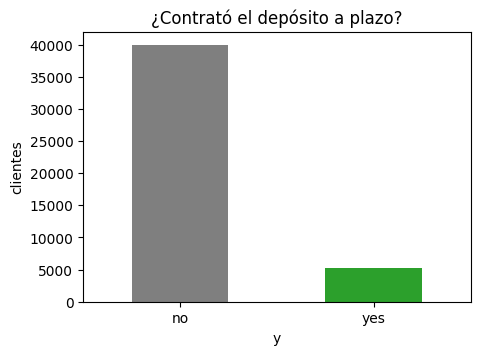

In [5]:
conteo = df["y"].value_counts()
porcentaje = df["y"].value_counts(normalize=True).mul(100).round(1)
display(pd.DataFrame({"cantidad": conteo, "porcentaje (%)": porcentaje}))

conteo.plot(kind="bar", color=["tab:gray", "tab:green"], figsize=(5, 3.5), rot=0,
            title="¿Contrató el depósito a plazo?")
plt.ylabel("clientes")
plt.show()

### Valores "unknown"

El dataset **no tiene celdas vacías**, pero varias columnas categóricas usan el texto `"unknown"` cuando no se conoce el dato.

In [6]:
print("Celdas vacías (NaN):", df.isna().sum().sum())
categoricas = [c for c in df.columns if df[c].dtype == "object" or str(df[c].dtype) == "str"]
unknown = {c: int((df[c] == "unknown").sum()) for c in categoricas}
pd.Series(unknown, name="cantidad de 'unknown'").to_frame().query("`cantidad de 'unknown'` > 0")

Celdas vacías (NaN): 0


,cantidad de 'unknown'
job,288
education,1857
contact,13020
poutcome,36959


## 4. Consideraciones importantes

1. **Clases desbalanceadas.** Solo ~12 % de los clientes contrató el depósito. Un modelo que responda siempre `"no"` obtiene **~88 % de Accuracy** sin haber aprendido nada. Por eso **Precision, Recall y F1-Score** de la clase `"yes"` son fundamentales para evaluar los modelos.
2. **La variable `duration`.** La duración de la llamada solo se conoce **después** de hacerla, y cuando `duration = 0` el resultado siempre es `"no"`. Los autores del dataset recomiendan **no usarla** si el objetivo es un modelo predictivo realista (uno que se use *antes* de llamar al cliente). Decidan si la incluyen o no y **justifiquen** su decisión en el análisis.
3. **Variables categóricas.** La red neuronal necesita números: hay que transformar las variables de texto.
4. **Escalas muy distintas.** Por ejemplo, `balance` va de miles de euros negativos a más de 100.000, mientras que `previous` suele estar entre 0 y 5.
5. **`pdays = -1`** no es un número de días: significa "nunca contactado antes".
6. **Separación de datos.** Todo lo que el preprocesamiento "aprende" (medias, escalas, categorías) debe calcularse **solo con los datos de entrenamiento**.

## 5. Su trabajo comienza aquí ⬇️

Sugerencia de estructura para el notebook de entrega:

1. Análisis exploratorio y preprocesamiento
2. Separación en entrenamiento / validación / prueba
3. Modelo base (MLP) y configuración de entrenamiento
4. Comparación de funciones de activación y de pérdida
5. Optimización y regularización
6. Evaluación final: Accuracy, Precision, Recall, F1-Score y matriz de confusión
7. Análisis de resultados y justificación de las mejoras

## 5.1 Fase 1 y 2: Preprocesamiento de Datos y División (Train / Validation / Test)

Para que la Red Neuronal Multicapa (MLP) converja adecuadamente y tenga capacidad de generalización, aplicamos las siguientes decisiones técnicas justificadas en las características del dataset *Bank Marketing*:

1. **Eliminación de la variable `duration` (Prevención de *Data Leakage*):**
   La duración de la llamada solo se conoce una vez finalizado el contacto telefónico (y si `duration = 0`, la variable objetivo es invariablemente `"no"`). Incluirla generaría fuga de información del futuro (*data leakage*), impidiendo usar el modelo de forma predictiva antes de contactar al cliente. Siguiendo la recomendación de los autores (Moro et al., 2014), se excluye del entrenamiento.
2. **Tratamiento especial de `pdays = -1`:**
   El valor `-1` indica que el cliente nunca fue contactado previamente (~81.7% de los casos). Para evitar que la red interprete `-1` como una magnitud numérica continua negativa, se crea la variable binaria `contactado_antes` (`1` si `pdays != -1`, `0` si `pdays == -1`) y se reemplaza el `-1` por `0`.
3. **Codificación de variables categóricas y binarias:**
   Las redes neuronales operan exclusivamente con tensores numéricos. Las variables binarias (`default`, `housing`, `loan` y el target `y`) se mapean a `0` y `1`. Las variables categóricas nominales (`job`, `marital`, `education`, `contact`, `month`, `poutcome`, incluyendo la categoría `"unknown"` como información explícita) se transforman mediante **One-Hot Encoding** (`drop_first=True` para evitar multicolinealidad), pasando a 42 variables predictoras.
4. **División Estratificada (70% Entrenamiento / 15% Validación / 15% Prueba):**
   Dado el fuerte desbalance de clases (88.3% `"no"` vs 11.7% `"yes"`), se utiliza muestreo estratificado (`stratify=y`) para conservar exactamente el 11.7% de casos positivos en los tres subconjuntos.
5. **Escalado Estandarizado (`StandardScaler`) sin Fuga de Datos:**
   Variables como `balance` (rango de miles de euros) y `previous` (unidades) tienen escalas muy dispares, lo que distorsiona los gradientes en el descenso del gradiente. Se aplica `StandardScaler` ($\mu=0, \sigma=1$) ajustando los parámetros (`fit`) **únicamente sobre el conjunto de entrenamiento** y transformando validación y prueba.
6. **Pesos de Clase (`class_weight`):**
   Para evitar que el modelo converja a la clase mayoritaria (`"no"`), se calculan pesos inversamente proporcionales a la frecuencia de cada clase en el conjunto de entrenamiento.

In [9]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

# 1. Eliminamos 'duration' para evitar fuga de datos (data leakage)
df_proc = df.drop(columns=["duration"]).copy()

# 2. Tratamiento de 'pdays = -1'
df_proc["contactado_antes"] = (df_proc["pdays"] != -1).astype(int)
df_proc["pdays"] = df_proc["pdays"].replace(-1, 0)

# 3. Codificación de variables binarias (0 y 1)
cols_binarias = ["default", "housing", "loan", "y"]
for col in cols_binarias:
    df_proc[col] = df_proc[col].map({"yes": 1, "no": 0})

# 4. One-Hot Encoding para variables categóricas
cols_categoricas = ["job", "marital", "education", "contact", "month", "poutcome"]
df_encoded = pd.get_dummies(df_proc, columns=cols_categoricas, drop_first=True, dtype=int)

print(f"Dimensiones tras codificación: {df_encoded.shape[0]} filas x {df_encoded.shape[1]} columnas")

# 5. Separación Estratificada: 70% Train, 15% Validation, 15% Test
X = df_encoded.drop(columns=["y"])
y = df_encoded["y"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# 6. Escalado de variables numéricas (fit SOLO en X_train)
cols_numericas = ["age", "balance", "day", "campaign", "pdays", "previous"]
scaler = StandardScaler()

X_train[cols_numericas] = scaler.fit_transform(X_train[cols_numericas])
X_val[cols_numericas] = scaler.transform(X_val[cols_numericas])
X_test[cols_numericas] = scaler.transform(X_test[cols_numericas])

# 7. Cálculo de pesos de clase para compensar el desbalance (88.3% vs 11.7%)
pesos = compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=y_train)
class_weights = {0: pesos[0], 1: pesos[1]}

# Resumen de verificación
resumen_split = pd.DataFrame({
    "Conjunto": ["Entrenamiento (70%)", "Validación (15%)", "Prueba (15%)"],
    "Filas": [X_train.shape[0], X_val.shape[0], X_test.shape[0]],
    "Features (X)": [X_train.shape[1], X_val.shape[1], X_test.shape[1]],
    "Proporción 'yes' (%)": [
        round(y_train.mean() * 100, 2),
        round(y_val.mean() * 100, 2),
        round(y_test.mean() * 100, 2)
    ]
})
display(resumen_split)
print(f"Pesos de clase calculados: Clase 0 ('no') = {class_weights[0]:.3f} | Clase 1 ('yes') = {class_weights[1]:.3f}")

Dimensiones tras codificación: 45211 filas x 43 columnas


,Conjunto,Filas,Features (X),Proporción 'yes' (%)
0,Entrenamiento (70%),31647,42,11.70
1,Validación (15%),6782,42,11.71
2,Prueba (15%),6782,42,11.69


Pesos de clase calculados: Clase 0 ('no') = 0.566 | Clase 1 ('yes') = 4.274
